# Tropical cyclones, seen from above

Where do tropical cyclones gather, when do they appear, and what can one exceptional storm reveal?

## Reading the visuals

In [21]:
from pathlib import Path
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.colors as mcolors
import seaborn as sns
import cartopy.crs as ccrs
import cartopy.feature as cfeature

DATA_PATH = Path("datasets/processed/cyclones_2010_2025.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["ISO_TIME"], keep_default_na=False, na_values=[""])
for field in ["LAT", "LON", "USA_WIND", "USA_PRES"]:
    df[field] = pd.to_numeric(df[field], errors="coerce")
df = df.sort_values(["SID", "ISO_TIME"]).reset_index(drop=True)
assert df["SID"].nunique() == 1667
assert df["ISO_TIME"].dt.year.between(2010, 2025).all()

basin_names = {"WP": "West Pacific", "EP": "East Pacific", "NA": "North Atlantic", "SI": "South Indian", "NI": "North Indian", "SP": "South Pacific", "SA": "South Atlantic"}
basin_order = ["WP", "EP", "NA", "SI", "NI", "SP", "SA"]
visits = df.groupby(["SID", "BASIN"]).size().rename("positions").reset_index().sort_values(["SID", "positions", "BASIN"], ascending=[True, False, True])
storms = df.groupby("SID", sort=False).agg(first_time=("ISO_TIME", "first"), first_lat=("LAT", "first"), first_lon=("LON", "first"), peak_wind=("USA_WIND", "max"))
storms["basin"] = visits.drop_duplicates("SID").set_index("SID")["BASIN"]
storms["hemisphere"] = np.where(storms["first_lat"] >= 0, "North", "South")
storms["first_month"] = storms["first_time"].dt.month

NAVY = "#14354A"
TEAL = "#157F86"
CORAL = "#DF6B4F"
GOLD = "#D69A34"
MUTED = "#61717B"
LAND = "#ECEBE7"
SEA = "#F6FAFA"
GRID = "#DDE5E5"
sns.set_theme(style="white", context="talk", font_scale=.82)
plt.rcParams.update({"figure.dpi": 115, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white", "font.family": "DejaVu Sans", "text.color": NAVY, "axes.labelcolor": NAVY, "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"})


def title_block(fig, title, subtitle, note):
    fig.text(.06, .965, title, ha="left", va="top", fontsize=21, fontweight="bold", color=NAVY)
    fig.text(.06, .905, subtitle, ha="left", va="top", fontsize=10.5, color=MUTED)
    fig.text(.06, .035, note, ha="left", va="bottom", fontsize=8.5, color=MUTED)


def world_map(ax):
    ax.set_global()
    ax.set_facecolor(SEA)
    ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor=LAND, edgecolor="none", zorder=2)
    ax.coastlines(resolution="110m", color="#B6C3C5", linewidth=.45, zorder=3)
    ax.spines["geo"].set_edgecolor("#C9D5D6")
    ax.spines["geo"].set_linewidth(.7)


def clean_axes(ax):
    ax.grid(axis="y", color=GRID, linewidth=.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(length=0)

## 1 · The global picture

### Storms follow ocean corridors

A world of tracks reveals the basic geography before any numbers appear.

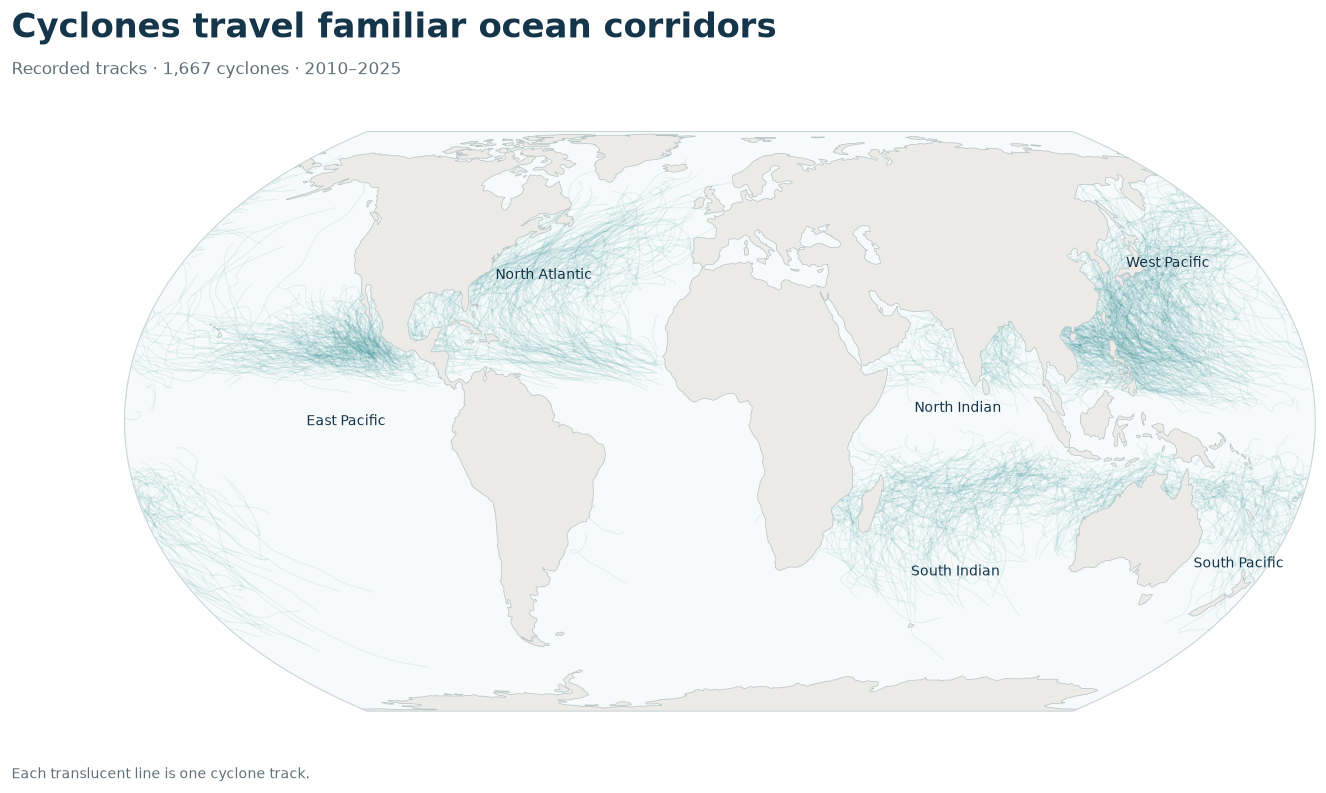

In [22]:
fig = plt.figure(figsize=(14, 7.2))
ax = fig.add_axes([.05, .12, .90, .70], projection=ccrs.EqualEarth())
world_map(ax)
for sid, track in df.groupby("SID", sort=False):
    x = ((track["LON"].to_numpy(dtype=float) + 180) % 360) - 180
    y = track["LAT"].to_numpy(dtype=float)
    jumps = np.flatnonzero(np.abs(np.diff(x)) > 180) + 1
    for indices in np.split(np.arange(len(x)), jumps):
        if len(indices) > 1:
            ax.plot(x[indices], y[indices], color=TEAL, alpha=.085, linewidth=.65, transform=ccrs.PlateCarree(), zorder=1, rasterized=True)
for lon, lat, label in [(-58, 34, "North Atlantic"), (-113, 0, "East Pacific"), (150, 37, "West Pacific"), (72, 3, "North Indian"), (78, -35, "South Indian"), (170, -33, "South Pacific")]:
    ax.text(lon, lat, label, transform=ccrs.PlateCarree(), ha="center", va="center", fontsize=8.5, color=NAVY, zorder=4)
title_block(fig, "Cyclones travel familiar ocean corridors", "Recorded tracks · 1,667 cyclones · 2010–2025", "Each translucent line is one cyclone track.")
plt.show()

The tracks cluster over tropical oceans and bend toward higher latitudes. Large gaps over land and near the equator make the pattern visible immediately.

### The strongest recorded storm

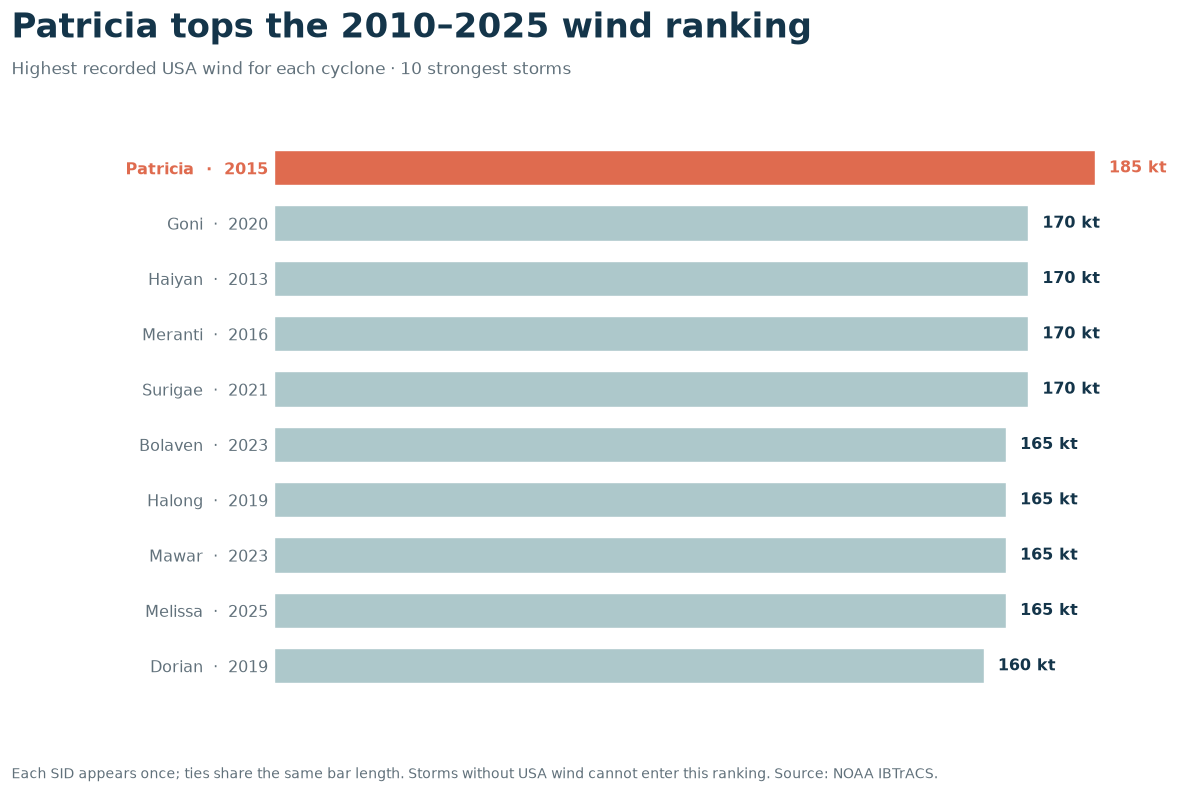

In [23]:
storm_names = df.groupby("SID")["NAME"].first()
ranked = storms.dropna(subset=["peak_wind"]).copy()
ranked["storm_name"] = storm_names
ranked["year"] = ranked["first_time"].dt.year
ranked = ranked.sort_values(["peak_wind", "storm_name"], ascending=[False, True]).head(10)
labels = [f"{row.storm_name.title()}  ·  {row.year}" for row in ranked.itertuples()]
values = ranked["peak_wind"].to_numpy()
colors = [CORAL if sid == "2015293N13266" else "#ADC8CB" for sid in ranked.index]
fig, ax = plt.subplots(figsize=(12, 7.2))
fig.subplots_adjust(left=.25, right=.91, top=.83, bottom=.12)
y = np.arange(len(ranked))
ax.barh(y, values, color=colors, height=.66)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(0, 205)
ax.set_xticks([])
for row, value in enumerate(values):
    ax.text(value + 3, row, f"{value:.0f} kt", va="center", fontsize=10, fontweight="bold", color=CORAL if row == 0 else NAVY)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0, labelsize=10)
ax.get_yticklabels()[0].set_color(CORAL)
ax.get_yticklabels()[0].set_fontweight("bold")
title_block(fig, "Patricia tops the 2010–2025 wind ranking", "Highest recorded USA wind for each cyclone · 10 strongest storms", "Each SID appears once; ties share the same bar length. Storms without USA wind cannot enter this ranking. Source: NOAA IBTrACS.")
plt.show()

At **185 kt**, Patricia stands 15 kt above the next highest recorded peaks in this processed file. The ranking sets up a closer look at how Patricia reached that extreme.

## 2 · Hurricane Patricia

Patricia's recorded path runs westward along the eastern Pacific, then curves toward Mexico. In this processed dataset, its peak USA wind is **185 kt**, the highest recorded peak among the 1,667 cyclones.

In [24]:
patricia_ids = df.loc[df["NAME"].str.upper().eq("PATRICIA") & df["ISO_TIME"].dt.year.eq(2015), "SID"].unique()
assert len(patricia_ids) == 1
patricia = df.loc[df["SID"].eq(patricia_ids[0])].sort_values("ISO_TIME").copy()
peak = patricia.loc[patricia["USA_WIND"].idxmax()]
start = patricia.iloc[0]
assert peak["USA_WIND"] == storms["peak_wind"].max()
wind_24h = patricia[["ISO_TIME", "USA_WIND"]].dropna().merge(patricia[["ISO_TIME", "USA_WIND"]].dropna().assign(ISO_TIME=lambda x: x["ISO_TIME"] + pd.Timedelta(hours=24)), on="ISO_TIME", suffixes=("_later", "_earlier"))
wind_24h["gain"] = wind_24h["USA_WIND_later"] - wind_24h["USA_WIND_earlier"]
fastest = wind_24h.loc[wind_24h["gain"].idxmax()]
rapid_start = fastest["ISO_TIME"] - pd.Timedelta(hours=24)
rapid_end = fastest["ISO_TIME"]
print(f"Patricia: {len(patricia)} positions, {start['ISO_TIME']:%d %b}–{patricia.iloc[-1]['ISO_TIME']:%d %b %Y}; peak {peak['USA_WIND']:.0f} kt; strongest observed 24-hour gain {fastest['gain']:.0f} kt.")

Patricia: 36 positions, 20 Oct–24 Oct 2015; peak 185 kt; strongest observed 24-hour gain 105 kt.


### The route toward Mexico

Color follows recorded wind speed along the track. The strongest part of Patricia's life occurred just offshore, before the track crossed Mexico's Pacific coast.

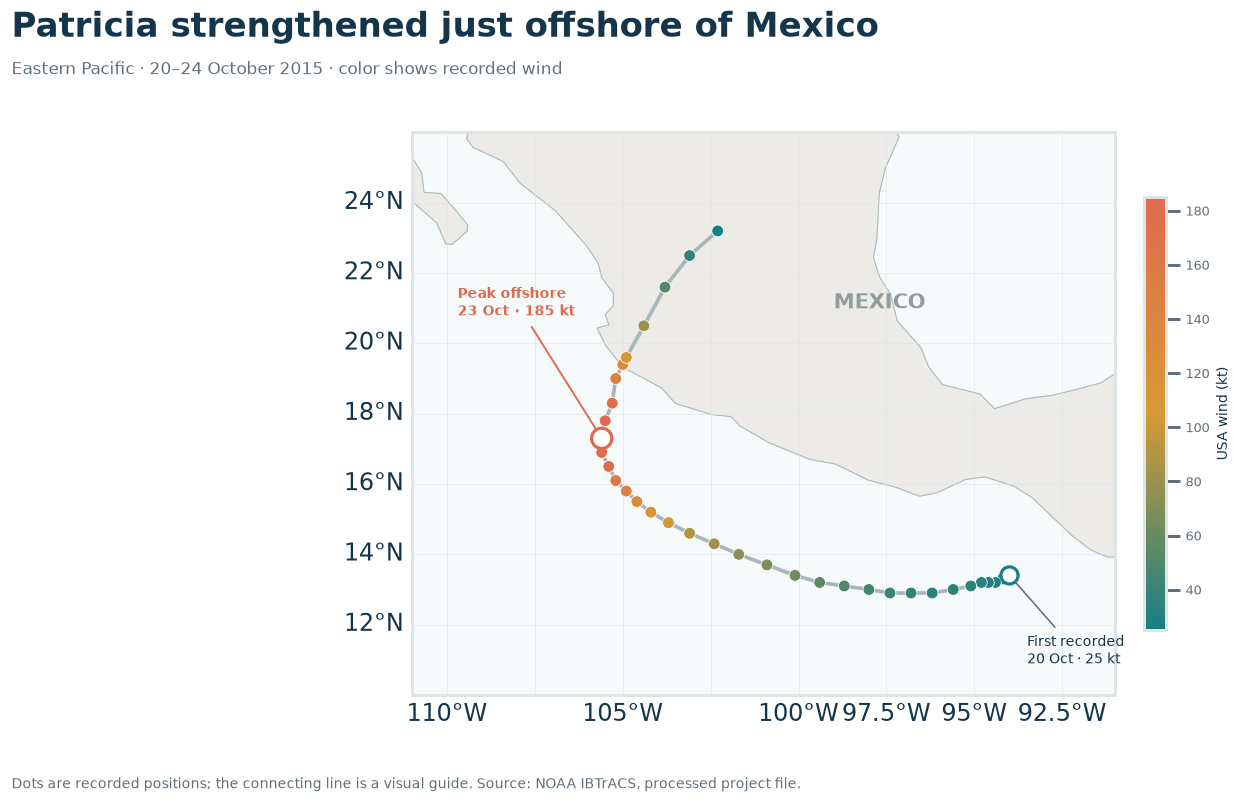

In [25]:
fig = plt.figure(figsize=(12, 7.3))
ax = fig.add_axes([.07, .15, .84, .67], projection=ccrs.PlateCarree())
ax.set_extent([-111, -91, 10, 26], crs=ccrs.PlateCarree())
ax.set_facecolor(SEA)
ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor=LAND, edgecolor="none", zorder=1)
ax.coastlines(resolution="110m", color="#AAB9BB", linewidth=.7, zorder=2)
ax.plot(patricia["LON"], patricia["LAT"], color="#A9B6B9", linewidth=2.3, transform=ccrs.PlateCarree(), zorder=3)
sc = ax.scatter(patricia["LON"], patricia["LAT"], c=patricia["USA_WIND"], cmap=sns.blend_palette([TEAL, GOLD, CORAL], as_cmap=True), vmin=25, vmax=185, s=54, edgecolors="white", linewidths=.5, transform=ccrs.PlateCarree(), zorder=4)
ax.scatter([start["LON"], peak["LON"]], [start["LAT"], peak["LAT"]], s=[115, 160], facecolors="white", edgecolors=[TEAL, CORAL], linewidths=2, transform=ccrs.PlateCarree(), zorder=5)
ax.annotate("First recorded\n20 Oct · 25 kt", xy=(start["LON"], start["LAT"]), xytext=(-93.5, 10.9), fontsize=9, color=NAVY, arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 1}, transform=ccrs.PlateCarree(), ha="left")
ax.annotate("Peak offshore\n23 Oct · 185 kt", xy=(peak["LON"], peak["LAT"]), xytext=(-109.7, 20.8), fontsize=9, fontweight="bold", color=CORAL, arrowprops={"arrowstyle": "-", "color": CORAL, "lw": 1.2}, transform=ccrs.PlateCarree(), ha="left")
ax.text(-99, 21, "MEXICO", fontsize=13, color="#909D9C", fontweight="bold", transform=ccrs.PlateCarree())
ax.gridlines(draw_labels={"bottom": "x", "left": "y"}, linewidth=.5, color=GRID, alpha=.7, x_inline=False, y_inline=False)
cbar = fig.colorbar(sc, ax=ax, orientation="vertical", fraction=.035, pad=.025, shrink=.77)
cbar.set_label("USA wind (kt)", fontsize=9)
cbar.ax.tick_params(labelsize=8)
title_block(fig, "Patricia strengthened just offshore of Mexico", "Eastern Pacific · 20–24 October 2015 · color shows recorded wind", "Dots are recorded positions; the connecting line is a visual guide. Source: NOAA IBTrACS, processed project file.")
plt.show()

### 24-hour wind change record

The shaded interval is the largest increase between two recorded wind estimates exactly 24 hours apart.

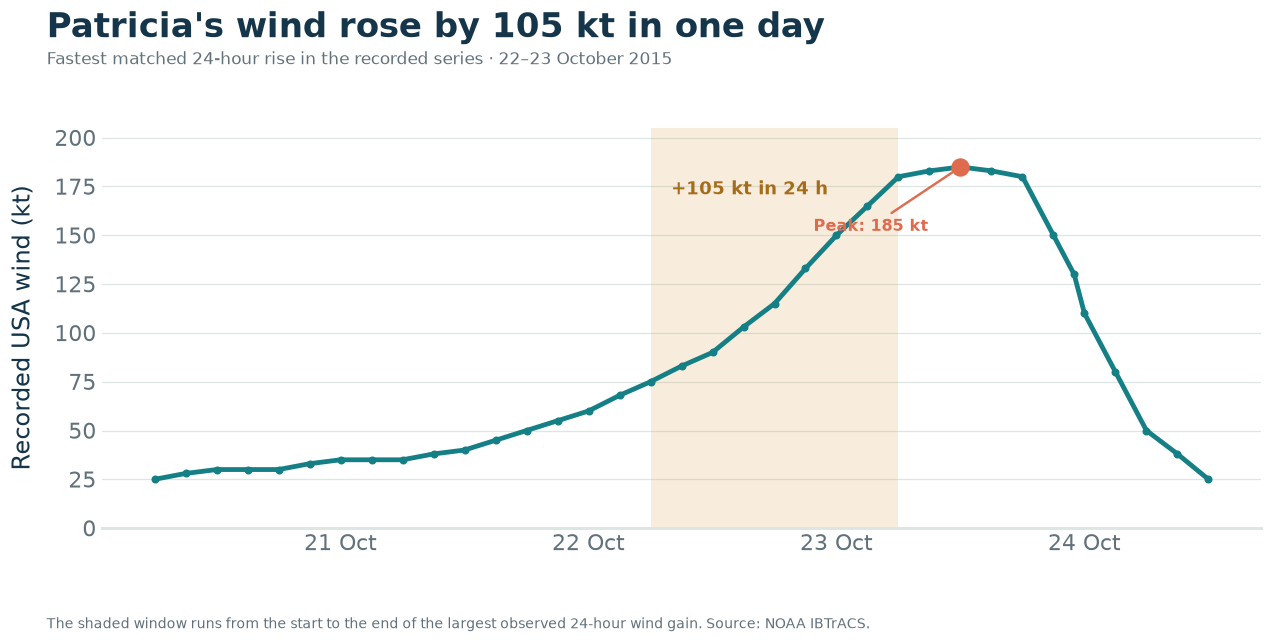

In [26]:
fig, ax = plt.subplots(figsize=(12, 5.8))
fig.subplots_adjust(left=.10, right=.94, top=.79, bottom=.19)
ax.axvspan(rapid_start, rapid_end, color=GOLD, alpha=.17, linewidth=0)
ax.plot(patricia["ISO_TIME"], patricia["USA_WIND"], color=TEAL, linewidth=3, marker="o", markersize=4)
ax.scatter([peak["ISO_TIME"]], [peak["USA_WIND"]], color=CORAL, s=100, zorder=5)
ax.annotate(f"Peak: {peak['USA_WIND']:.0f} kt", xy=(peak["ISO_TIME"], peak["USA_WIND"]), xytext=(-92, -40), textcoords="offset points", fontsize=10, fontweight="bold", color=CORAL, arrowprops={"arrowstyle": "-", "color": CORAL})
ax.text(rapid_start + pd.Timedelta(hours=2), 171, f"+{fastest['gain']:.0f} kt in 24 h", fontsize=11, fontweight="bold", color="#A56D19")
ax.set_ylabel("Recorded USA wind (kt)", labelpad=12)
ax.set_ylim(0, 205)
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
clean_axes(ax)
title_block(fig, "Patricia's wind rose by 105 kt in one day", "Fastest matched 24-hour rise in the recorded series · 22–23 October 2015", "The shaded window runs from the start to the end of the largest observed 24-hour wind gain. Source: NOAA IBTrACS.")
plt.show()

The sharpest 24-hour rise is **105 kt**, from 75 to 180 kt between 06:00 UTC on 22 October and 06:00 UTC on 23 October. Patricia reached 185 kt six hours later.

### Pressure fell as wind accelerated

Pressure offers a second, familiar way to read the same intensification. Lower central pressure accompanies the stronger recorded wind.

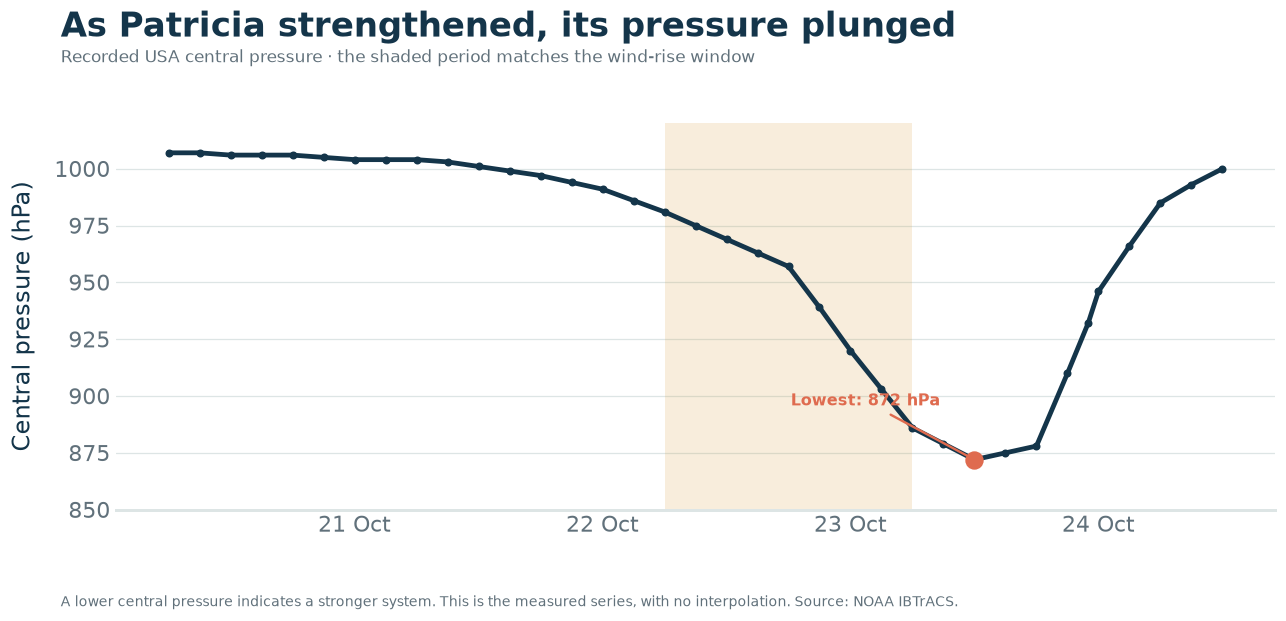

In [27]:
low_pressure = patricia.loc[patricia["USA_PRES"].idxmin()]
fig, ax = plt.subplots(figsize=(12, 5.6))
fig.subplots_adjust(left=.10, right=.94, top=.79, bottom=.19)
ax.axvspan(rapid_start, rapid_end, color=GOLD, alpha=.17, linewidth=0)
ax.plot(patricia["ISO_TIME"], patricia["USA_PRES"], color=NAVY, linewidth=3, marker="o", markersize=4)
ax.scatter([low_pressure["ISO_TIME"]], [low_pressure["USA_PRES"]], color=CORAL, s=100, zorder=5)
ax.annotate(f"Lowest: {low_pressure['USA_PRES']:.0f} hPa", xy=(low_pressure["ISO_TIME"], low_pressure["USA_PRES"]), xytext=(-115, 34), textcoords="offset points", fontsize=10, fontweight="bold", color=CORAL, arrowprops={"arrowstyle": "-", "color": CORAL})
ax.set_ylabel("Central pressure (hPa)", labelpad=12)
ax.set_ylim(850, 1020)
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
clean_axes(ax)
title_block(fig, "As Patricia strengthened, its pressure plunged", "Recorded USA central pressure · the shaded period matches the wind-rise window", "A lower central pressure indicates a stronger system. This is the measured series, with no interpolation. Source: NOAA IBTrACS.")
plt.show()

Patricia's lowest recorded pressure is **872 hPa**, at the same 23 October observation as its 185 kt peak wind. The subsequent rise in pressure accompanies weakening after the peak.

## 3 · Patricia from space

The animation below uses **observed** 10–11 µm infrared window brightness temperatures (`IRWIN`) from [NOAA NCEI HURSAT-B1 v06](https://www.ncei.noaa.gov/products/hurricane-satellite-data). The 301 × 301 storm-centered grids have 0.07° spacing (about 8 km). This local Patricia subset contains **35 GOES-15 observations, one every three hours from 20 October 06:00 to 24 October 12:00 UTC**. GOES-13 observations at the same times are present but are not mixed into this sequence.

Colors encode measured brightness temperature in °C on a fixed scale: the coldest, usually highest cloud tops appear white/magenta/red; warmer low clouds or cloud-free surfaces appear gray. This is an **infrared enhancement, not a true-color image**. Brightness temperature cannot by itself establish cloud height or wind speed. The source is sampled every three hours, so motion between frames is not observed; masked pixels remain transparent. The fixed map uses the file's latitude/longitude coordinates and a Natural Earth coastline, while the observation window follows the storm. No cloud fields are interpolated or simulated.

In [28]:
from datetime import datetime, timezone
from pathlib import Path
from netCDF4 import Dataset
import numpy as np

hursat_dir = Path("datasets/HURSAT_PATRICIA")
files = sorted(hursat_dir.glob("*PATRICIA.2015.10.*.hursat-b1.v06.nc"))
assert files, f"No Patricia HURSAT-B1 v06 files found in {hursat_dir}"

with Dataset(files[0]) as sample:
    ir_var = sample.variables["IRWIN"]
    print("Storm:", sample.TC_name, "| product:", sample.title, "| version: v06")
    print("IRWIN:", ir_var.long_name, "| units:", ir_var.units,
          "| dimensions:", ir_var.dimensions, "| shape:", ir_var.shape)
    for name in ("lat", "lon", "htime"):
        var = sample.variables[name]
        print(f"{name}: units={var.units}, shape={var.shape}, range={np.min(var[:])}–{np.max(var[:])}")
    assert ir_var.units == "Kelvin" and ir_var.dimensions == ("htime", "lat", "lon")
    assert sample.variables["lat"].units == "degrees_north"
    assert sample.variables["lon"].units == "degrees_east"
    assert sample.variables["htime"].units.startswith("days since 1970-01-01")

observations = []
for path in files:
    with Dataset(path) as ds:
        if ds.Satellite_Name != "GOES-15":
            continue 
        assert ds.TC_name == "PATRICIA"
        lat = np.asarray(ds.variables["lat"][:], dtype=float)
        lon = np.asarray(ds.variables["lon"][:], dtype=float)
        assert lat.size == lon.size == 301 and np.all(np.diff(lat) > 0) and np.all(np.diff(lon) > 0)

        bt_k = np.ma.asarray(ds.variables["IRWIN"][0], dtype=np.float32)
        assert bt_k.shape == (lat.size, lon.size)
        timestamp = datetime.fromtimestamp(round(float(ds.variables["htime"][0]) * 86400), tz=timezone.utc)
        observations.append({"time": timestamp, "lat": lat, "lon": lon,
                             "bt_c": np.ma.filled(bt_k - 273.15, np.nan)})

observations.sort(key=lambda item: item["time"])
assert len(observations) == 35
assert all((b["time"] - a["time"]).total_seconds() == 3 * 3600
           for a, b in zip(observations, observations[1:]))
print(f"Loaded {len(observations)} GOES-15 IR frames: "
      f"{observations[0]['time']:%d %b %Y %H:%M}–{observations[-1]['time']:%d %b %Y %H:%M} UTC")

Storm: PATRICIA | product: HURSAT-B1 | version: v06
IRWIN: Brightness Temperature in (10.2-11.1 um) | units: Kelvin | dimensions: ('htime', 'lat', 'lon') | shape: (1, 301, 301)
lat: units=degrees_north, shape=(301,), range=2.8999996185302734–23.899999618530273
lon: units=degrees_east, shape=(301,), range=-104.5–-83.5
htime: units=days since 1970-01-01 00:00, shape=(1,), range=16728.249999999534–16728.249999999534
Loaded 35 GOES-15 IR frames: 20 Oct 2015 06:00–24 Oct 2015 12:00 UTC


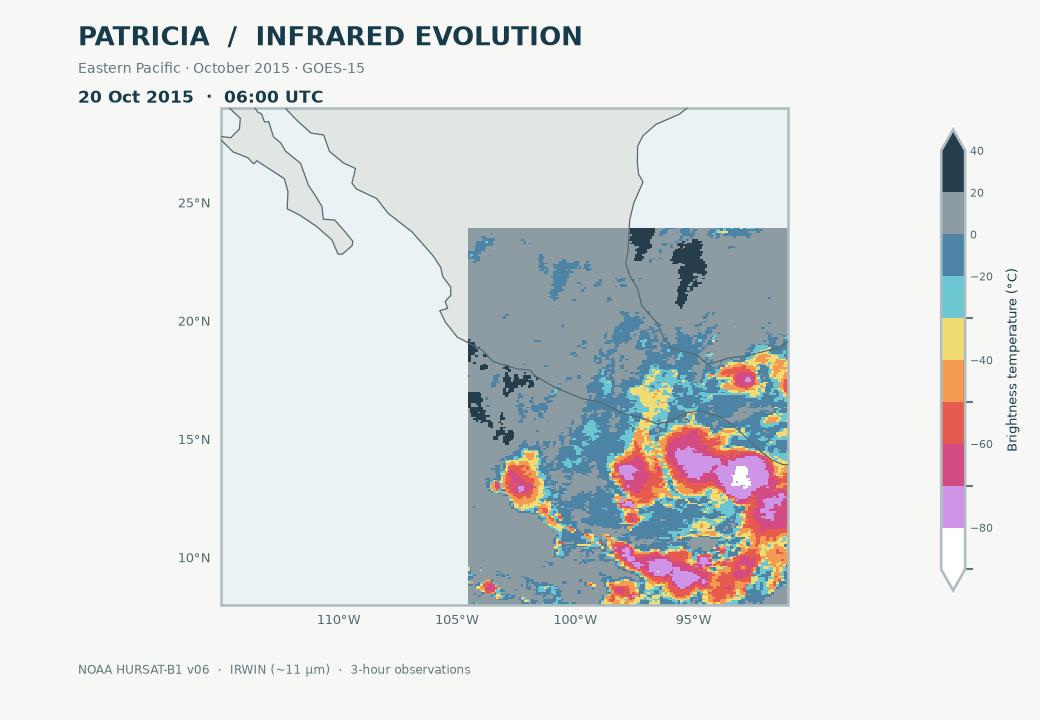

In [30]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
import cartopy.crs as ccrs
import cartopy.feature as cfeature

bounds_c = [-100, -80, -70, -60, -50, -40, -30, -20, 0, 20, 40]
ir_colors = ["#ffffff", "#ce94e8", "#d24b83", "#e75b4e", "#f39b50",
             "#f1db73", "#6bc6d1", "#4d83a5", "#8d9ca2", "#263e4c"]
ir_cmap = ListedColormap(ir_colors, name="patricia_enhanced_ir")
ir_cmap.set_bad((0, 0, 0, 0))
ir_norm = BoundaryNorm(bounds_c, ir_cmap.N, clip=True)
projection = ccrs.PlateCarree()

fig = plt.figure(figsize=(10.4, 7.2), facecolor="#f7f8f6")
ax = fig.add_axes([0.075, 0.16, 0.82, 0.69], projection=projection)
ax.set_extent([-115, -91, 8, 29], crs=projection)
ax.set_facecolor("#eaf2f3")
ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="#e2e6e3", edgecolor="none", zorder=0)

def pixel_extent(frame):
    lon, lat = frame["lon"], frame["lat"]
    return (lon[0] - (lon[1] - lon[0]) / 2,
            lon[-1] + (lon[-1] - lon[-2]) / 2,
            lat[0] - (lat[1] - lat[0]) / 2,
            lat[-1] + (lat[-1] - lat[-2]) / 2)

image = ax.imshow(observations[0]["bt_c"], origin="lower", extent=pixel_extent(observations[0]),
                  transform=projection, cmap=ir_cmap, norm=ir_norm,
                  interpolation="nearest", zorder=1)
ax.coastlines(resolution="110m", color="#526b72", linewidth=0.9, zorder=3)
ax.set_xticks([-110, -105, -100, -95], crs=projection)
ax.set_yticks([10, 15, 20, 25], crs=projection)
ax.set_xticklabels(["110°W", "105°W", "100°W", "95°W"])
ax.set_yticklabels(["10°N", "15°N", "20°N", "25°N"])
ax.tick_params(colors="#536a73", labelsize=9, length=0, pad=7)
ax.spines["geo"].set_edgecolor("#aebec0")

fig.text(0.075, 0.965, "PATRICIA  /  INFRARED EVOLUTION", color="#173b4b",
         fontsize=19, fontweight="bold", ha="left", va="top")
fig.text(0.075, 0.914, "Eastern Pacific · October 2015 · GOES-15", color="#617782",
         fontsize=10, ha="left", va="top")
time_label = fig.text(0.075, 0.875, "", color="#173b4b", fontsize=12,
                      fontweight="bold", ha="left", va="top")
fig.text(0.075, 0.06, "NOAA HURSAT-B1 v06  ·  IRWIN (~11 µm)  ·  3-hour observations",
         color="#617782", fontsize=8.5, ha="left", va="bottom")

cax = fig.add_axes([0.905, 0.18, 0.023, 0.64])
colorbar = fig.colorbar(ScalarMappable(norm=ir_norm, cmap=ir_cmap), cax=cax,
                       boundaries=bounds_c, ticks=[-80, -60, -40, -20, 0, 20, 40],
                       extend="both")
colorbar.set_label("Brightness temperature (°C)", color="#173b4b", fontsize=9, labelpad=9)
colorbar.ax.tick_params(colors="#536a73", labelsize=8, length=0)
colorbar.outline.set_edgecolor("#aebec0")

def update_frame(index):
    frame = observations[index]
    image.set_data(frame["bt_c"])
    image.set_extent(pixel_extent(frame))
    time_label.set_text(frame["time"].strftime("%d %b %Y  ·  %H:%M UTC"))
    return image, time_label

animation = FuncAnimation(fig, update_frame, frames=len(observations),
                          interval=350, blit=False, repeat=True)
output_path = Path("outputs/patricia_hursat_ir_2015.gif")
output_path.parent.mkdir(parents=True, exist_ok=True)
animation.save(output_path, writer=PillowWriter(fps=3), dpi=100)
plt.close(fig)
from IPython.display import Image, display
display(Image(filename=str(output_path)))